In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2_contingency

In [16]:
# Path.cwd()
project_root = Path.cwd().parent
data_path = project_root / "data" / "raw" / "deliveries_train.csv"
df = pd.read_csv(data_path)

In [25]:
df.head()

,order_id,order_placed_at,restaurant_id,cuisine,restaurant_avg_prep_minutes,city_zone,distance_km,items_count,order_subtotal,courier_vehicle,courier_trips_completed,weather,delivery_minutes
0,700001,2025-03-01 10:00:00,10,pizza,12.9,suburbs_north,2.2,2,19.24,scooter,50.0,cloudy,29
1,700003,2025-03-01 11:06:00,5,mexican,12.4,uptown,5.3,1,8.36,bike,1255.0,clear,36
2,700004,2025-03-01 11:15:00,59,pizza,11.7,suburbs_south,2.6,3,27.38,scooter,276.0,clear,31
3,700005,2025-03-01 11:28:00,51,indian,17.0,downtown,3.3,1,8.00,bike,664.0,cloudy,34
4,700006,2025-03-01 11:40:00,104,thai,11.5,suburbs_south,11.6,2,18.96,car,38.0,rain,54


In [33]:
print(f"Number of Observations: {len(df)}")
print(f"shape of the DataFrame: {df.shape}")
print(f"Number of Features: {df.shape[1]}")
print(f"Missing Values are: \n{(df.isna().sum() / len(df)) * 100}")

Number of Observations: 8000
shape of the DataFrame: (8000, 13)
Number of Features: 13
Missing Values are: 
order_id                       0.0000
order_placed_at                0.0000
restaurant_id                  0.0000
cuisine                        0.0000
restaurant_avg_prep_minutes    0.0000
city_zone                      0.0000
distance_km                    0.0000
items_count                    0.0000
order_subtotal                 0.0000
courier_vehicle                0.0000
courier_trips_completed        4.1125
weather                        2.8500
delivery_minutes               0.0000
dtype: float64


In [35]:
df[df["courier_trips_completed"].isna()].head(10)

,order_id,order_placed_at,restaurant_id,cuisine,restaurant_avg_prep_minutes,city_zone,distance_km,items_count,order_subtotal,courier_vehicle,courier_trips_completed,weather,delivery_minutes
25,700031,2025-03-01 17:12:00,76,mexican,10.0,uptown,2.6,6,89.37,car,NaN,cloudy,23
39,700047,2025-03-01 19:26:00,5,mexican,12.4,uptown,4.7,2,28.27,scooter,NaN,clear,33
82,700099,2025-03-02 18:09:00,113,mexican,13.2,midtown,3.9,2,19.96,car,NaN,cloudy,33
89,700106,2025-03-02 19:10:00,52,mexican,5.5,uptown,4.9,2,18.51,bike,NaN,rain,37
113,700140,2025-03-03 12:58:00,98,salads,11.1,midtown,4.6,1,12.60,scooter,NaN,clear,39
149,700183,2025-03-04 10:36:00,6,sushi,16.8,midtown,1.2,1,13.74,bike,NaN,clear,23
157,700191,2025-03-04 11:16:00,14,burgers,6.4,downtown,2.1,2,30.66,scooter,NaN,clear,9
162,700199,2025-03-04 13:02:00,134,mexican,10.8,midtown,4.1,3,30.69,bike,NaN,clear,36
165,700203,2025-03-04 13:29:00,8,burgers,12.1,uptown,2.7,2,18.91,scooter,NaN,NaN,26
191,700231,2025-03-05 10:19:00,86,chinese,11.8,suburbs_south,10.5,2,23.48,car,NaN,clear,46


C:\Users\Dell\AppData\Local\Temp\ipykernel_2412\632745549.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(


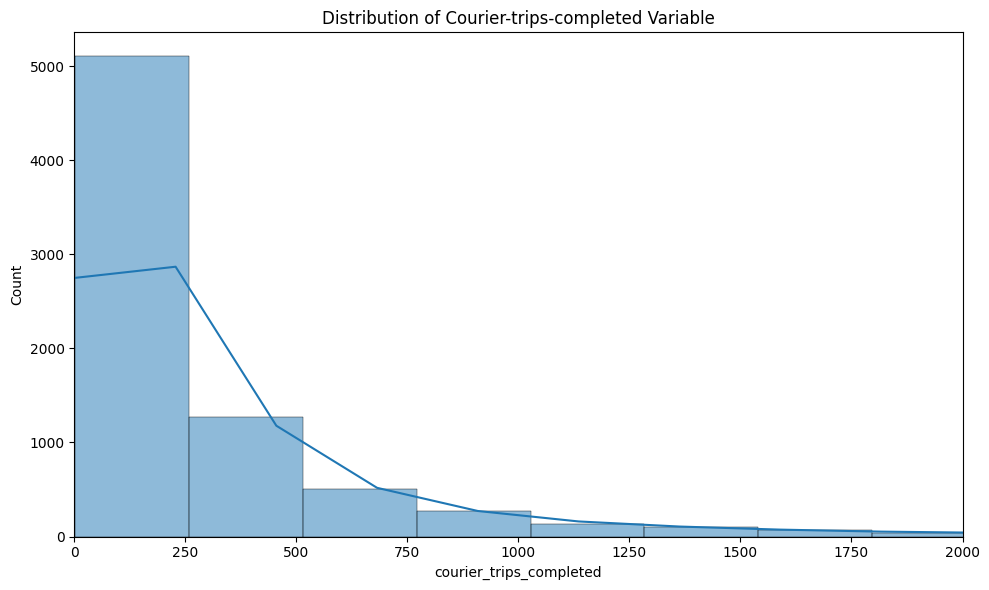

In [42]:
fig , ax = plt.subplots(figsize=(10,6))
sns.histplot(
    data= df,
    x = "courier_trips_completed",
    palette= "Set2",
    ax= ax , kde= True)

ax.set_title("Distribution of Courier-trips-completed Variable")
ax.set_ylabel("Count")
plt.xlim(0 , 2000)
plt.tight_layout()
plt.show()


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   order_id                     8000 non-null   int64  
 1   order_placed_at              8000 non-null   object 
 2   restaurant_id                8000 non-null   int64  
 3   cuisine                      8000 non-null   object 
 4   restaurant_avg_prep_minutes  8000 non-null   float64
 5   city_zone                    8000 non-null   object 
 6   distance_km                  8000 non-null   float64
 7   items_count                  8000 non-null   int64  
 8   order_subtotal               8000 non-null   float64
 9   courier_vehicle              8000 non-null   object 
 10  courier_trips_completed      7671 non-null   float64
 11  weather                      7772 non-null   object 
 12  delivery_minutes             8000 non-null   int64  
dtypes: float64(4), int

In [44]:
# Converting order_placed_at to a datetime type
df["order_placed_at"] = pd.to_datetime(df["order_placed_at"])
# Extracting potenial meaningful features from the datetime
df["ordered_dayofweek"] = df["order_placed_at"].dt.dayofweek
df["ordered_weekend"] = df["ordered_dayofweek"].isin([4,5]).astype(int)

In [ ]:
df.head()

,order_id,order_placed_at,restaurant_id,cuisine,restaurant_avg_prep_minutes,city_zone,distance_km,items_count,order_subtotal,courier_vehicle,courier_trips_completed,weather,delivery_minutes,ordered_dayofweek,ordered_weekend
0,700001,2025-03-01 10:00:00,10,pizza,12.9,suburbs_north,2.2,2,19.24,scooter,50.0,cloudy,29,5,1
1,700003,2025-03-01 11:06:00,5,mexican,12.4,uptown,5.3,1,8.36,bike,1255.0,clear,36,5,1
2,700004,2025-03-01 11:15:00,59,pizza,11.7,suburbs_south,2.6,3,27.38,scooter,276.0,clear,31,5,1
3,700005,2025-03-01 11:28:00,51,indian,17.0,downtown,3.3,1,8.00,bike,664.0,cloudy,34,5,1
4,700006,2025-03-01 11:40:00,104,thai,11.5,suburbs_south,11.6,2,18.96,car,38.0,rain,54,5,1


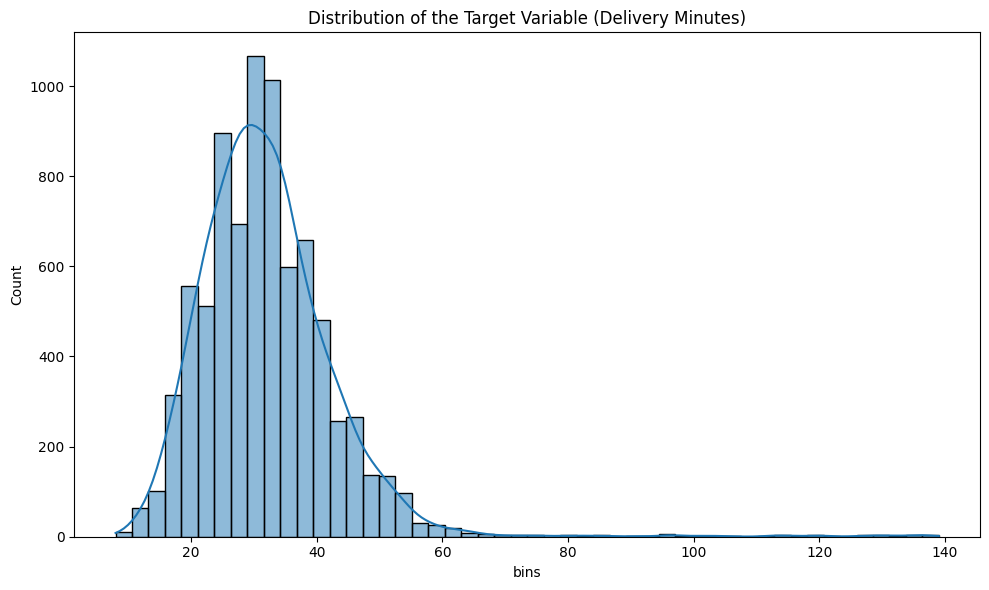

In [49]:
fig, ax = plt.subplots(figsize = (10,6))
sns.histplot(
    data = df,
    x = "delivery_minutes",
    kde = True,
    ax= ax,
    bins = 50
)

ax.set_title("Distribution of the Target Variable (Delivery Minutes)")
ax.set_xlabel("bins")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

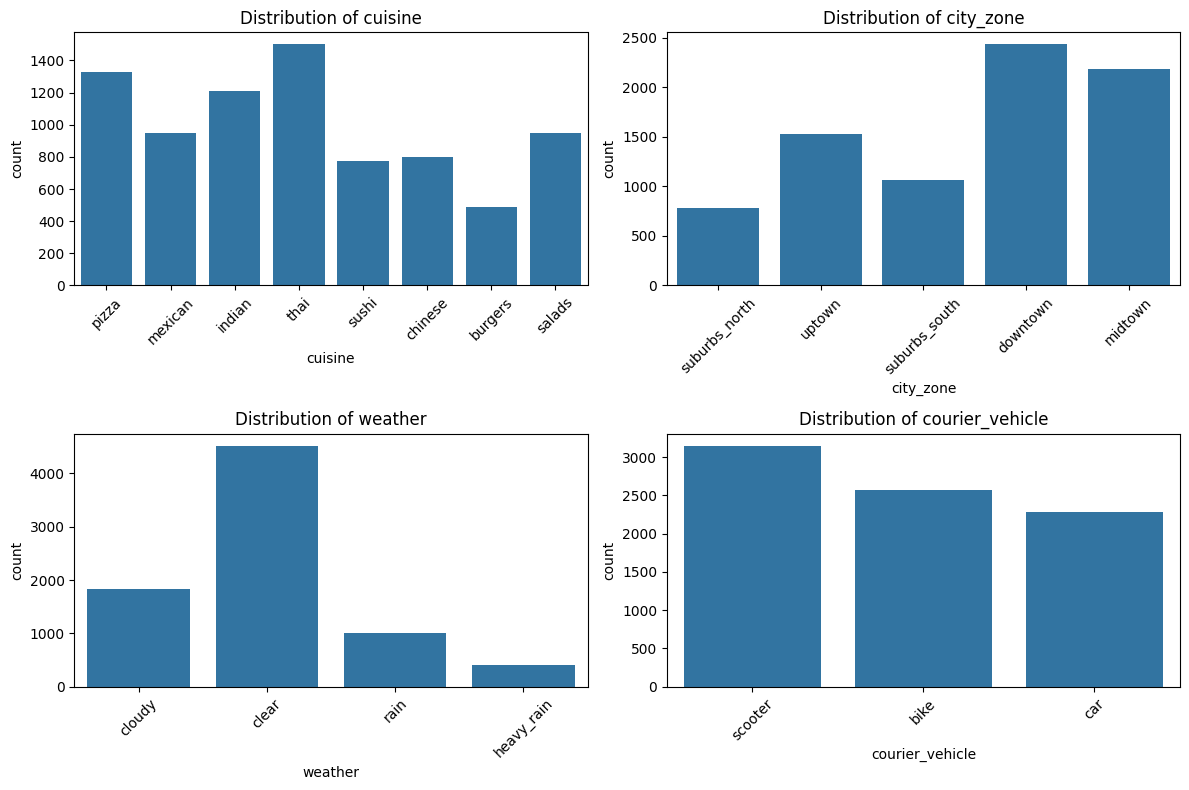

In [52]:
nominal_cols = [
    "cuisine",
    "city_zone",
    "weather",
    "courier_vehicle"
]

fig , axes = plt.subplots(2,2,figsize=(12,8))
for col , ax in zip(nominal_cols , axes.flat):
    sns.countplot(data= df , x = col , ax= ax)
    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

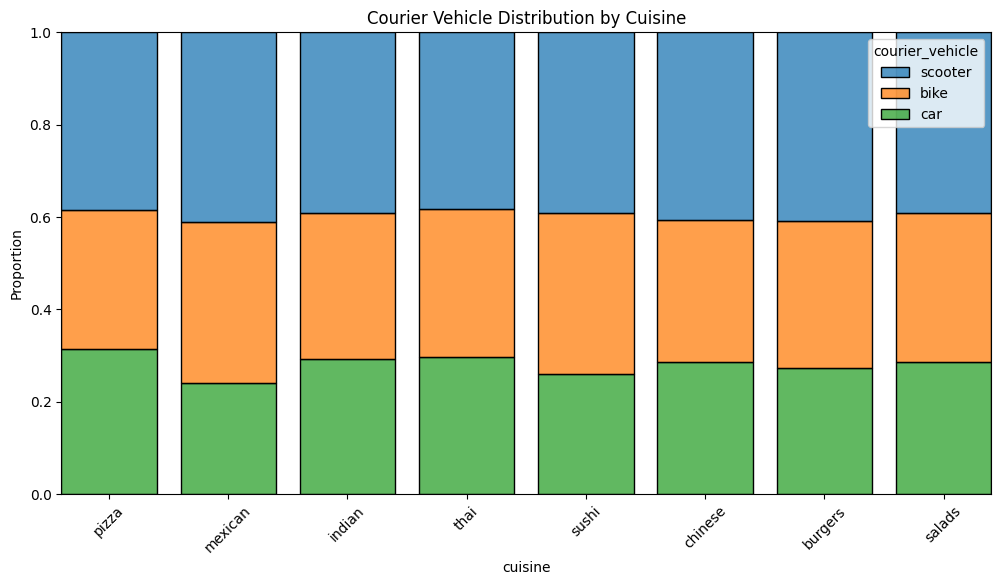

In [55]:
# Proportion of Courier Vehicle levels across different cuisines
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x="cuisine", hue='courier_vehicle', multiple='fill', shrink=0.8)
plt.title('Courier Vehicle Distribution by Cuisine')
plt.xticks(rotation=45)
plt.ylabel('Proportion')
plt.show()

In [69]:
df.describe()

,order_id,order_placed_at,restaurant_id,restaurant_avg_prep_minutes,distance_km,items_count,order_subtotal,courier_trips_completed,delivery_minutes,ordered_dayofweek,ordered_weekend
count,8000.000000,8000,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,7671.000000,8000.000000,8000.000000,8000.000000
mean,704989.228375,2025-05-31 19:02:44.077500160,81.143375,13.843662,3.581812,2.79650,32.235950,355.163734,32.048750,2.983375,0.277125
min,700001.000000,2025-03-01 10:00:00,1.000000,5.000000,0.600000,1.00000,8.000000,1.000000,8.000000,0.000000,0.000000
25%,702482.750000,2025-04-14 19:14:00,41.000000,11.500000,2.000000,2.00000,15.770000,62.000000,25.000000,1.000000,0.000000
50%,704969.500000,2025-05-31 12:35:00,81.000000,13.400000,2.900000,2.00000,27.390000,147.000000,31.000000,3.000000,0.000000
75%,707519.250000,2025-07-17 20:40:15,122.000000,16.800000,4.400000,4.00000,42.575000,355.000000,37.000000,5.000000,1.000000
max,710000.000000,2025-08-31 23:42:00,160.000000,22.300000,13.300000,8.00000,127.640000,45151.000000,139.000000,6.000000,1.000000
std,2894.680014,NaN,46.528641,4.062165,2.330241,1.65482,20.951454,910.360810,11.144972,2.014784,0.447607


In [68]:
df[["courier_trips_completed"]].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

,courier_trips_completed
count,7671.000000
mean,355.163734
std,910.360810
min,1.000000
50%,147.000000
75%,355.000000
90%,787.000000
95%,1261.000000
99%,3231.700000
max,45151.000000


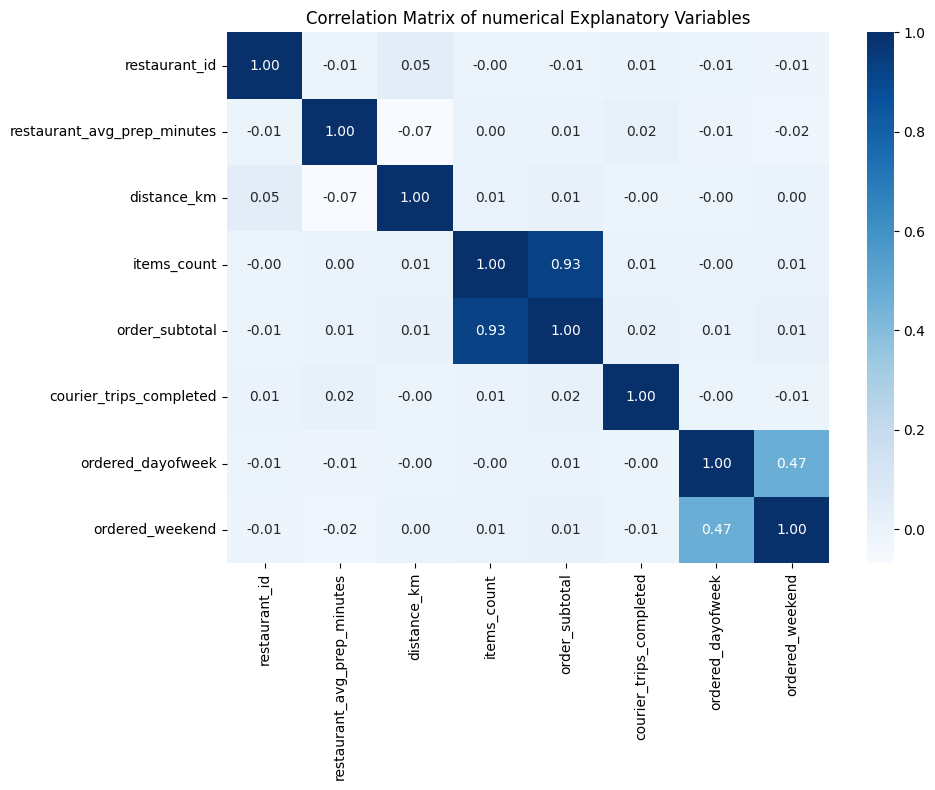

In [76]:
numerical_cols = [
    "restaurant_id",
    "restaurant_avg_prep_minutes",
    "distance_km",
    "items_count",
    "order_subtotal",
    "courier_trips_completed",
    "ordered_dayofweek",
    "ordered_weekend"
]

corr_matrix = df[numerical_cols].corr("spearman")
plt.figure(figsize=(10,8))
sns.heatmap(
    data= corr_matrix,
    annot= True,
    fmt= ".2f",
    cmap="Blues"
)
plt.title("Correlation Matrix of numerical Explanatory Variables")
plt.tight_layout()
plt.show()

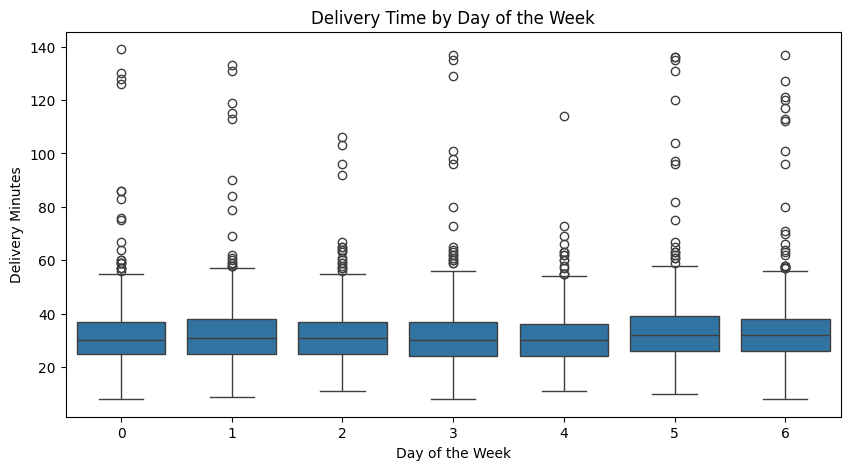

In [72]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="ordered_dayofweek",
    y="delivery_minutes"
)

plt.title("Delivery Time by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Delivery Minutes")
plt.show()

In [90]:
def cramer_v(x,y):
    contingency_table = pd.crosstab(x,y)
    chi2 , p_value  = chi2_contingency(contingency_table)[0:2]
    # Calculating Cramer V (chi2 / (n * min(r - 1, k - 1))) ** 0.5)
    # n is the number of total obsercations , r is the number of rows , k is the number of columns
    n = contingency_table.sum().sum()
    r , k = contingency_table.shape
    cramer_v = np.sqrt(
    chi2 / (n * min(r - 1, k - 1)))

    print(f"Chi_Square: {chi2}")
    print(f"P_Value: {p_value}")
    print(f"Cramer V: {cramer_v}")
    # Interpreting the P-Value
    alpha = 0.05

    if p_value < alpha:
        print("Reject H0: the variables are associated.")
    else:
        print("Fail to reject H0: insufficient evidence of association.")

    return cramer_v , p_value

In [91]:
for col in nominal_cols:
    Cramer_V , p_value = cramer_v(df[col] , df["delivery_minutes"])
    print(f"{col}")
    print()

Chi_Square: 2328.8831964254696
P_Value: 1.3560433666920845e-175
Cramer V: 0.20392939939147836
Reject H0: the variables are associated.
cuisine

Chi_Square: 2121.994826079986
P_Value: 2.339631500150943e-233
Cramer V: 0.2575118216995087
Reject H0: the variables are associated.
city_zone

Chi_Square: 545.0444615723715
P_Value: 2.972774670192589e-17
Cramer V: 0.15289347170165532
Reject H0: the variables are associated.
weather

Chi_Square: 343.97833054482055
P_Value: 5.886367635612406e-10
Cramer V: 0.1466241646491167
Reject H0: the variables are associated.
courier_vehicle



In [96]:
association_matrix = pd.DataFrame(
    index=nominal_cols,
    columns=nominal_cols,
    dtype=float)

for col1 in nominal_cols:
    for col2 in nominal_cols:
        if col1 == col2:
            association_matrix.loc[col1 , col2] = 1
        else:
            association_matrix.loc[col1 , col2] = cramer_v(df[col1] , df[col2])[0] # i did sliced only the first index beacuse it is the cramer v value
association_matrix

Chi_Square: 1301.5183124271425
P_Value: 1.4717111371663263e-256
Cramer V: 0.2016741115347932
Reject H0: the variables are associated.
Chi_Square: 15.466150349974312
P_Value: 0.7988563397486517
Cramer V: 0.02575515041254776
Fail to reject H0: insufficient evidence of association.
Chi_Square: 22.114474881036763
P_Value: 0.07629262135813021
Cramer V: 0.03717734094935782
Fail to reject H0: insufficient evidence of association.
Chi_Square: 1301.5183124271425
P_Value: 1.4717111371663263e-256
Cramer V: 0.2016741115347932
Reject H0: the variables are associated.
Chi_Square: 10.211369954587498
P_Value: 0.5974232197532463
Cramer V: 0.02092738586797022
Fail to reject H0: insufficient evidence of association.
Chi_Square: 536.0190751561876
P_Value: 1.3064914264316611e-110
Cramer V: 0.18303330898298736
Reject H0: the variables are associated.
Chi_Square: 15.466150349974312
P_Value: 0.7988563397486517
Cramer V: 0.02575515041254776
Fail to reject H0: insufficient evidence of association.
Chi_Square: 1

,cuisine,city_zone,weather,courier_vehicle
cuisine,1.000000,0.201674,0.025755,0.037177
city_zone,0.201674,1.000000,0.020927,0.183033
weather,0.025755,0.020927,1.000000,0.018465
courier_vehicle,0.037177,0.183033,0.018465,1.000000


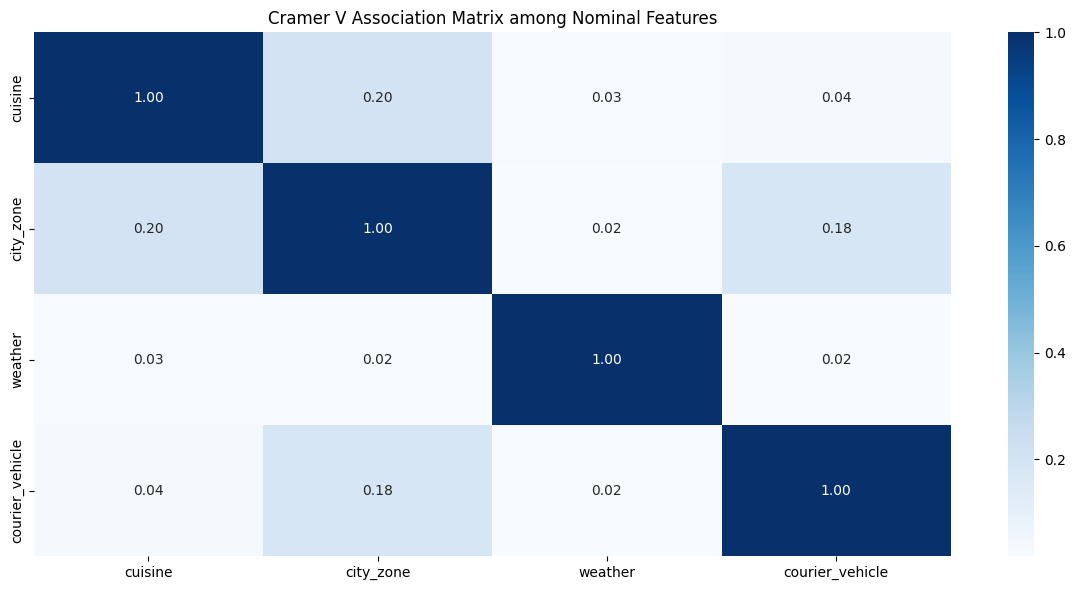

In [99]:
plt.figure(figsize=(12,6))
sns.heatmap(data= association_matrix , annot= True , fmt= ".2f" , cmap= "Blues")
plt.title("Cramer V Association Matrix among Nominal Features")
plt.tight_layout()
plt.show()